# 03 descriptive analysis

Calculate neighborhood-level statistics and descriptive visualizations from actual annual data.

Technical evidence for the confirmed Bremen project. Primary comparison: 2024 Ortsteile. No historical change claim; original data preserved.

## Setup and relative paths

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'analysis_common.py').exists(), 'Run from root or notebooks directory'
sys.path.insert(0, str(ROOT / 'src'))
from analysis_common import load_analysis, FEATURES
def read(relative):
    return pd.read_csv(ROOT / relative, dtype={'geo_code': str})
def show_figure(name):
    display(Image(filename=str(ROOT / 'results' / 'figures' / name)))


## Data loading and preparation

In [2]:
from descriptive_analysis import run
frame = load_analysis()

## Calculation and validation

In [3]:
statistics = run()
display(statistics)
display(read('results/indicator_correlations.csv'))

,feature,count,mean,std,min,25%,50%,75%,max,unit,year,population
0,unemployment,79.0,11.861742,5.553563,2.5896,7.40875,10.9762,16.16985,27.5409,%,2024,complete-case Ortsteile; unweighted
1,employment,79.0,58.630339,5.312910,44.1589,55.64405,59.4037,62.20865,72.7138,%,2024,complete-case Ortsteile; unweighted
2,benefit_receipt,79.0,14.843829,8.392421,1.7015,8.30390,13.2323,20.53200,34.6216,%,2024,complete-case Ortsteile; unweighted


,feature,unemployment,employment,benefit_receipt
0,unemployment,1.000000,-0.667381,0.973856
1,employment,-0.667381,1.000000,-0.587853
2,benefit_receipt,0.973856,-0.587853,1.000000


## Results, visualization and interpretation

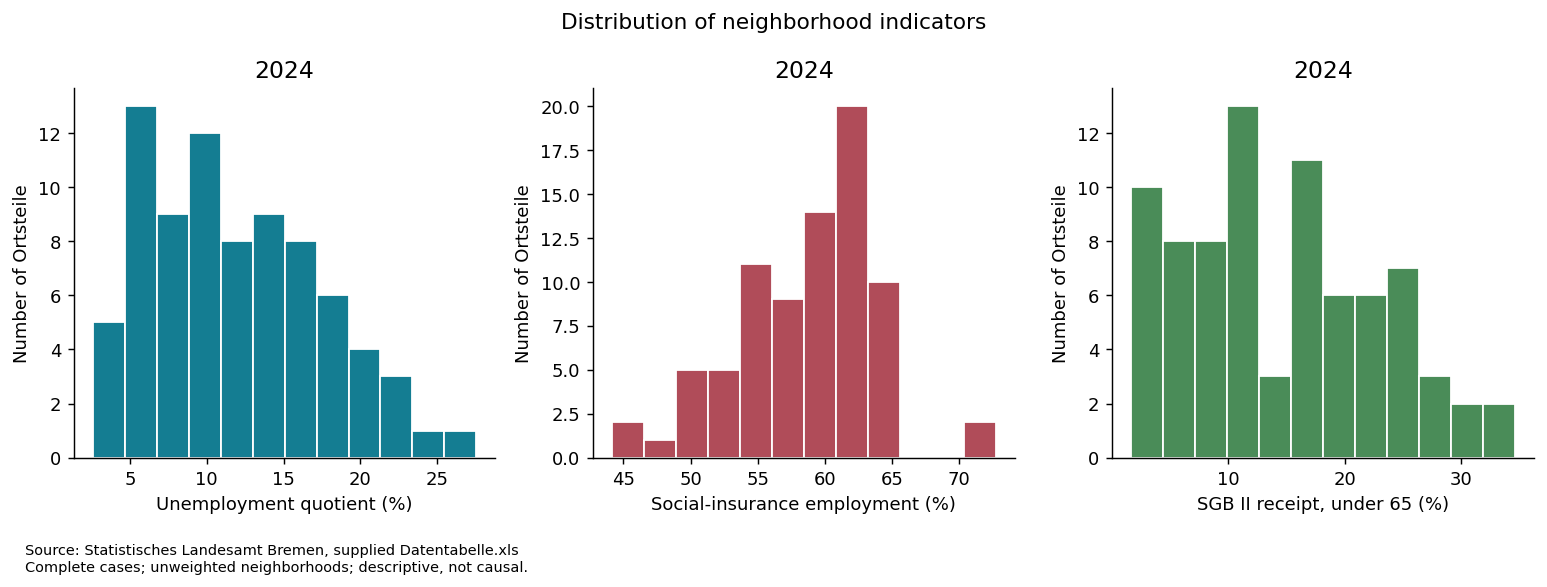

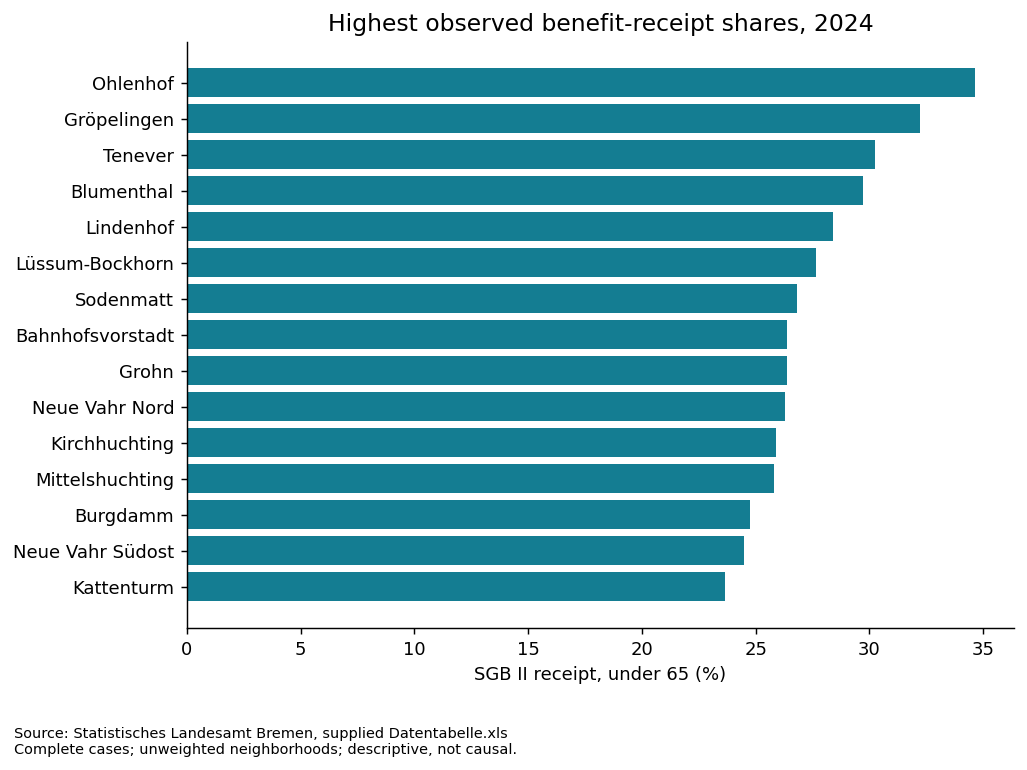

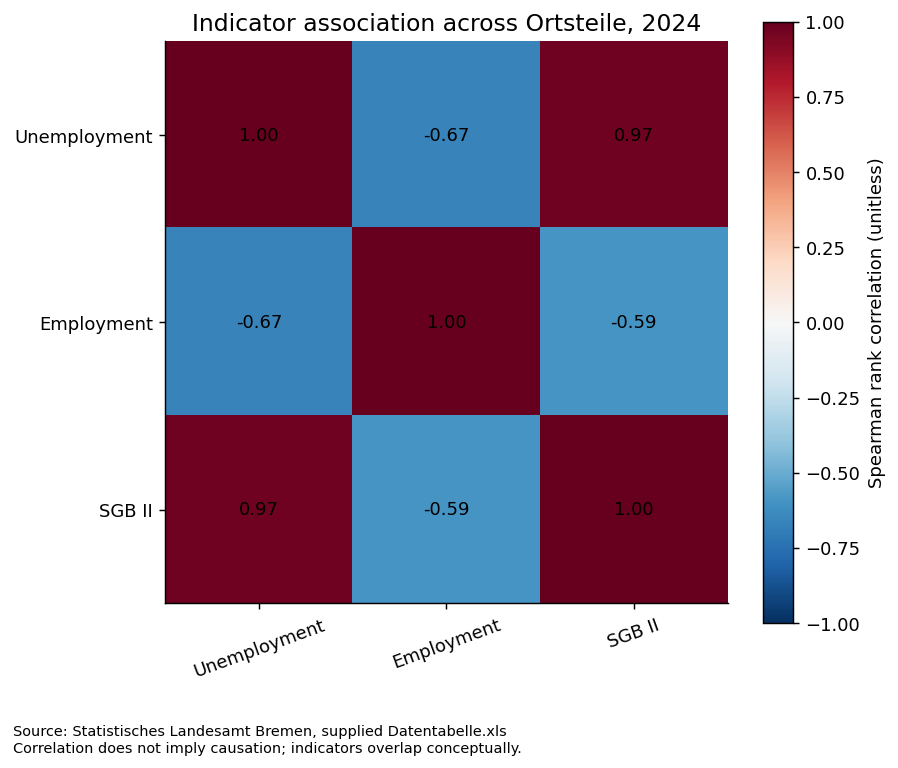

# Descriptive evidence

Reporting year 2024; 79 complete-case Ortsteile of 88 workbook Ortsteile. Every number is computed from the supplied workbook. Percentages have different denominators, documented in analysis/data_dictionary.csv. Means are unweighted neighborhood means, not Bremen population rates. Available-case statistics are exported separately to expose coverage effects.

- Unemployment quotient (%): 2.59 in Seehausen to 27.54 in Ohlenhof; neighborhood mean 11.86, median 10.98.
- Social-insurance employment (%): 44.16 in Fähr-Lobbendorf to 72.71 in Seehausen; neighborhood mean 58.63, median 59.40.
- SGB II receipt, under 65 (%): 1.70 in Borgfeld to 34.62 in Ohlenhof; neighborhood mean 14.84, median 13.23.

Unemployment versus benefit receipt Spearman correlation: 0.974. These are descriptive associations within the covered sample, with no causal or significance claims. The overlapping constructs motivate sensitivity tests.

Figures: indicator_distributions.png shows the spread; benefit_receipt_comparison.png shows the highest 15 observed shares; correlation_matrix.png shows pairwise Spearman association. Exact figure data is the complete-case subset of ortsteil_analysis_ready.csv. Excluded places may differ systematically; rankings are not citywide censuses of every neighborhood.

Historical changes and trend charts are withheld: boundary and definition stability are not established. Historical observation tables remain available for source review, without change estimates. Nominal taxpayer income is not used as current household income.


In [4]:
show_figure('indicator_distributions.png')
show_figure('benefit_receipt_comparison.png')
show_figure('correlation_matrix.png')
display(Markdown((ROOT / 'results/descriptive_findings.md').read_text(encoding='utf-8')))

## Assumptions and limits

Complete-case scoring; no imputation. Different indicator denominators, correlated labour-market measures, unavailable 2024 income, unknown exact reference dates and incomplete historical boundary/definition metadata limit interpretation. Rankings apply only to the covered sample. Clusters are nominal. See analysis/dataset_validation.md and docs/methods.md. Tables are exported by reusable scripts; important figures appear in results/figures/.